# Fuzzy Mamdani Berbasis Literatur untuk Penilaian Awal Kualitas Air Budidaya Ikan

**Tujuan.** Menilai suhu, pH, dan *dissolved oxygen* (DO) dengan satu model Mamdani. Model menghasilkan satu variabel kualitas air dengan tiga kategori (*Excellent*, *Good*, *Poor*) dan skor centroid pada skala 0–100.

**Konteks.** Rentang contoh penerapan berasal dari studi **kolam lele bioflok**. Kerangka model dapat dipakai untuk konteks lain setelah rentang dan aturan diperiksa untuk konteks tersebut. Kategori menyatakan profil tiga indikator yang diukur.

**Hasil yang tersimpan.** 27/27 kombinasi status murni dan 11/11 skenario sesuai dengan kelas yang diharapkan. Kesesuaian dengan WQD mencapai **44,02%** pada sampel dalam domain.

**Cara menjalankan di Colab.** Unggah notebook ini ke Google Colab. Pilih **Runtime → Run all**. Saat Bagian 7 meminta unggahan, pilih **WQD.xlsx** versi 1. Pilihan lain adalah unggah **WQD.xlsx** lewat panel **Files** sebelum menjalankan notebook. CPU standar cukup. [Unduh data dari Mendeley](https://data.mendeley.com/datasets/y78ty2g293/1)

**Alur.** Rujukan → parameter dan *rule base* tetap → cek skenario dan batas → contoh hitung → baca WQD mentah → evaluasi kesesuaian.

## 1. Dasar literatur dan asal keputusan

Pujiharsono dan Kurnianto [1] menggunakan suhu, pH, dan DO pada kolam lele bioflok. Tabel 1–3 memberi rentang untuk tiga kondisi pertumbuhan. Pembahasan Tabel 4 memberi prioritas pada indikator yang paling bermasalah dalam pemetaan kondisi. Angka di bawah mengikuti Tabel 1–3.

| Input | Critical | Caution | Optimal | Rujukan |
|---|---|---|---|---|
| Suhu (°C) | <16 atau >32 | 16–24 atau 31–32 | 25–30 | [1], Tabel 1 |
| pH | <4 atau >11 | 4–6,4 atau 8,6–11 | 6,5–8,5 | [1], Tabel 2 |
| DO (mg/L) | <0,5 | 0,5–1,7 | >1,7 | [1], Tabel 3 |

**Adaptasi untuk tugas.** Artikel memakai dua *output fuzzy sets* dan kemudian memetakan skor ke tiga kondisi. Di sini kami memakai tiga *output fuzzy sets* langsung. *Excellent* berarti semua indikator optimal, *Good* berarti ada indikator *Caution* dan semuanya setidaknya dapat diterima, dan *Poor* berarti ada indikator kritis. Nama kategori tersebut adalah pemetaan proyek. Maknanya mengikuti prinsip pada pembahasan Tabel 4 [1].

| Bagian model | Dasar keputusan |
|---|---|
| Tiga input dan kondisi dasarnya | Tabel 1–3 [1]. Studi patin [2] dan nila [3] juga memakai ketiga indikator tersebut untuk konteksnya sendiri. |
| Prioritas kondisi kritis | Pembahasan Tabel 4 [1]. Kode di bawah menerjemahkannya menjadi tiga aturan dengan MIN/MAX. |
| Transisi antarstatus input | Rancangan proyek. Gunakan celah antarrentang pada tabel sebagai transisi linear. Pada batas tunggal, gunakan setengah lebar 0,5 °C, 0,05 unit pH, atau 0,05 mg/L. Ini mengikuti setengah langkah penulisan angka pada tabel tiap parameter (1 °C untuk suhu dan 0,1 untuk pH serta DO). |
| Segitiga output dan skala skor | Rancangan proyek. Pusat 20 (*Poor*), 50 (*Good*), dan 80 (*Excellent*) dengan setengah lebar 20. MIN untuk clipping, MAX untuk aggregation, dan centroid untuk skor. |
| Label prediksi dan seri | Rancangan proyek. Pilih kelas dengan aktivasi terbesar. Pada seri, prioritasnya *Poor*, lalu *Good*, lalu *Excellent*. |
| Domain yang diproses | Pemeriksaan input eksperimen. Nilai harus berhingga dengan suhu 0–50 °C, pH 0–14, dan DO ≥0 mg/L. |

Konfigurasi berikut ditetapkan sebelum membaca WQD. Semua baris WQD yang memenuhi domain dapat dipakai untuk mengukur kesesuaian model tetap. Pembagian data latih dan uji diperlukan bila parameter atau aturan dipelajari dari data.

[Artikel utama, Tabel 1–4 dan Gambar 4](https://jtsiskom.undip.ac.id/article/download/13209/12555)

## 2. Definisikan membership function

Setiap batas transisi adalah pasangan $ (a,b) $. Derajat berpindah secara linear dari 0 ke 1 antara $ a $ dan $ b $.

$$
r(x;a,b)=\operatorname{clip}\!\left(\frac{x-a}{b-a},0,1\right)
$$

Untuk dua batas berurutan, selisih $ r_i-r_{i+1} $ memberikan derajat zona di antaranya. Jika suatu status muncul di dua zona, seperti *Critical* untuk suhu terlalu rendah dan terlalu tinggi, derajat kedua zona dijumlahkan. Ketiga status dari satu input berjumlah satu.

In [ ]:
from io import BytesIO
from itertools import product
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.patches import Rectangle
from PIL import Image as PILImage
from sklearn.metrics import classification_report, confusion_matrix

FEATURES = ["Temperature (°C)", "pH", "Dissolved oxygen (mg/L)"]
STATES = ["Critical", "Caution", "Optimal"]
CLASSES = ["Excellent", "Good", "Poor"]
PRIORITY = np.array(["Poor", "Good", "Excellent"])
SCORE_GRID = np.linspace(0, 100, 1001)
OUTPUT_CENTERS = np.array([20, 50, 80])
OUTPUT_HALF_WIDTH = 20
TIE_TOLERANCE = 1e-10

# Tiap input: batas awal/akhir transisi, diikuti status zona dari kiri ke kanan.
INPUT_MEMBERSHIPS = {
    "Temperature (°C)": (
        [(15.5, 16.5), (24, 25), (30, 31), (31.5, 32.5)],
        ["Critical", "Caution", "Optimal", "Caution", "Critical"],
    ),
    "pH": (
        [(3.95, 4.05), (6.4, 6.5), (8.5, 8.6), (10.95, 11.05)],
        ["Critical", "Caution", "Optimal", "Caution", "Critical"],
    ),
    "Dissolved oxygen (mg/L)": (
        [(0.45, 0.55), (1.65, 1.75)],
        ["Critical", "Caution", "Optimal"],
    ),
}


def membership(values, feature):
    '''Hitung derajat Critical, Caution, dan Optimal untuk satu input.'''
    transitions, zones = INPUT_MEMBERSHIPS[feature]
    start, end = np.array(transitions).T
    ramps = np.clip((values[:, None] - start) / (end - start), 0, 1)
    boundaries = np.column_stack([np.ones(len(values)), ramps, np.zeros(len(values))])
    zone_degrees = boundaries[:, :-1] - boundaries[:, 1:]
    return np.column_stack([
        zone_degrees[:, np.array(zones) == state].sum(axis=1) for state in STATES
    ])


output_sets = np.maximum(
    0, 1 - np.abs(SCORE_GRID - OUTPUT_CENTERS[:, None]) / OUTPUT_HALF_WIDTH
)

## 3. Rule base dan inferensi Mamdani

| ID | IF | THEN | Dasar |
|---|---|---|---|
| R1 | Suhu, pH, **dan** DO *Optimal* | *Excellent* | Semua indikator berada pada kondisi optimal. [1], Tabel 1–4. |
| R2 | Minimal satu input *Caution* **dan** ketiga input berada pada *Caution* atau *Optimal* | *Good* | Ada hambatan pada salah satu indikator, dengan syarat kondisi pada indikator lain masih dapat diterima. [1], pembahasan Tabel 4. |
| R3 | Suhu, pH, **atau** DO *Critical* | *Poor* | Satu kondisi kritis cukup untuk memicu kategori terendah. [1], pembahasan Tabel 4. |

Ketiga baris mengelompokkan 27 kombinasi status murni. Saat input berada pada transisi, beberapa aturan dapat aktif bersamaan. Untuk fitur $i$, gunakan $O_i$, $W_i$, dan $C_i$ untuk *Optimal*, *Caution*, dan *Critical*.

$$
\alpha_{\mathrm{Excellent}} = \min_i O_i,\qquad
\alpha_{\mathrm{Good}} = \min\!\left(\max_i W_i,\ \min_i \max(W_i,O_i)\right),\qquad
\alpha_{\mathrm{Poor}} = \max_i C_i
$$

Setiap kelas $j$ punya segitiga $\nu_j(z)=\max(0,1-|z-m_j|/20)$. Potong tinggi tiap segitiga dengan $\alpha_j$, lalu ambil MAX di setiap titik $z$. Gunakan centroid diskret untuk merangkum hasil aggregation pada grid 0–100 berlangkah 0,1.

$$
\nu_{\mathrm{agg}}(z)=\max_j\min(\alpha_j,\nu_j(z)),\qquad
s=\frac{\sum_z z\,\nu_{\mathrm{agg}}(z)}{\sum_z\nu_{\mathrm{agg}}(z)}
$$

Kategori berasal dari aktivasi tertinggi. Skor centroid merangkum semua aturan yang aktif, sehingga kategori selalu ditampilkan bersama skor.

In [ ]:
def input_domain(samples):
    '''Periksa kelayakan tiga kolom input sebelum inferensi.'''
    temperature, ph, oxygen = samples.T
    return (
        np.isfinite(samples).all(axis=1)
        & (temperature >= 0) & (temperature <= 50)
        & (ph >= 0) & (ph <= 14)
        & (oxygen >= 0)
    )


def rule_activation(degrees):
    '''Gabungkan derajat input sesuai tiga aturan.'''
    critical, caution, optimal = degrees.transpose(2, 0, 1)
    poor = critical.max(axis=1)
    good = np.minimum(caution.max(axis=1), np.maximum(caution, optimal).min(axis=1))
    excellent = optimal.min(axis=1)
    return np.column_stack([poor, good, excellent])


def aggregate_output(activation):
    '''Potong tiap output set lalu ambil MAX.'''
    clipped = np.minimum(activation[:, :, None], output_sets[None, :, :])
    return clipped.max(axis=1)


def predict(samples):
    '''Terima baris suhu, pH, DO. Kembalikan kelas, skor, dan aktivasi.'''
    values = np.atleast_2d(np.asarray(samples, dtype=float))
    if values.ndim != 2 or values.shape[1] != 3:
        raise ValueError("Masukkan tiga kolom: suhu (°C), pH, dan DO (mg/L).")
    if not input_domain(values).all():
        raise ValueError("Ada nilai input yang tidak berhingga atau di luar domain.")

    degrees = np.stack([membership(values[:, i], feature) for i, feature in enumerate(FEATURES)], axis=1)
    activation = rule_activation(degrees)
    aggregated = aggregate_output(activation)
    score = (aggregated * SCORE_GRID).sum(axis=1) / aggregated.sum(axis=1)
    strongest = activation.max(axis=1, keepdims=True)
    winners = activation >= strongest - TIE_TOLERANCE
    return PRIORITY[winners.argmax(axis=1)], score, activation

### Visualisasi membership function

Garis menunjukkan rentang setiap status dan daerah transisi. Untuk DO, bahu kanan mengikuti definisi *Optimal* pada Tabel 3. Nilai pH dan DO sama-sama ditampilkan pada skala aslinya.

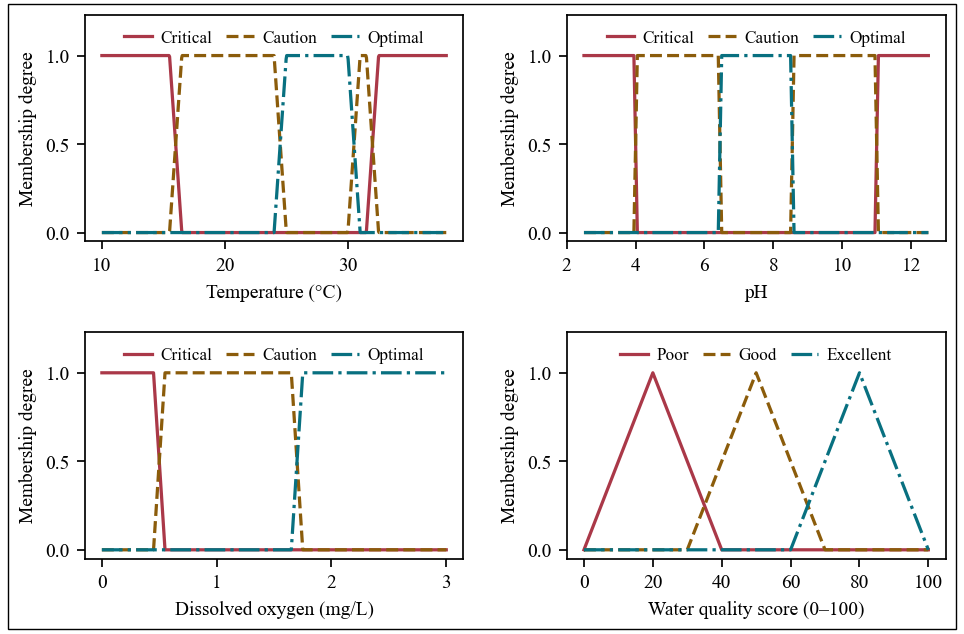

Figure 1 Literature-anchored input memberships and project output sets


In [ ]:
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "font.size": 9, "axes.titlesize": 9, "legend.fontsize": 8,
    "legend.frameon": False, "grid.color": "#d6d6d6",
})
class_colors = {"Poor": "#aa3848", "Good": "#8b5c0b", "Excellent": "#087080"}
line_styles = ["-", "--", "-."]
figure_dir = Path("jmasif_mamdani_literatur")
figure_dir.mkdir(exist_ok=True)
figures = []


def new_figure(rows, columns, height_cm):
    fig, axes = plt.subplots(
        rows, columns, figsize=(15.8 / 2.54, height_cm / 2.54), layout="constrained"
    )
    fig.get_layout_engine().set(w_pad=0.12, h_pad=0.10)
    fig.add_artist(Rectangle(
        (0.008, 0.008), 0.984, 0.984, transform=fig.transFigure,
        fill=False, linewidth=0.65, edgecolor="black",
    ))
    return fig, axes


def save_plot(fig, name, caption):
    path = figure_dir / f"{name}.tiff"
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=600)
        buffer.seek(0)
        with PILImage.open(buffer) as raster:
            raster.convert("RGB").save(path, compression="tiff_lzw", dpi=(600, 600))
    with BytesIO() as preview:
        fig.savefig(preview, format="png", dpi=155)
        display(Image(data=preview.getvalue(), alt=caption))
    print(caption)
    figures.append((path, caption))
    plt.close(fig)


fig, axes = new_figure(2, 2, 10.4)
limits = [(10, 38), (2.5, 12.5), (0, 3)]
for ax, feature, (lo, hi) in zip(axes.flat, FEATURES, limits):
    grid = np.linspace(lo, hi, 601)
    for state, color, style, curve in zip(STATES, class_colors.values(), line_styles, membership(grid, feature).T):
        ax.plot(grid, curve, style, color=color, label=state)
    ax.set(xlabel=feature, ylabel="Membership degree", ylim=(-0.05, 1.23))
    ax.legend(loc="upper center", ncol=3, columnspacing=0.8, handlelength=1.6, handletextpad=0.5)

ax = axes[1, 1]
for label, curve, style in zip(PRIORITY, output_sets, line_styles):
    ax.plot(SCORE_GRID, curve, style, color=class_colors[label], label=label)
ax.set(xlabel="Water quality score (0–100)", ylabel="Membership degree", ylim=(-0.05, 1.23))
ax.legend(loc="upper center", ncol=3, columnspacing=0.8, handlelength=1.6, handletextpad=0.5)
save_plot(fig, "figure_01_memberships", "Figure 1 Literature-anchored input memberships and project output sets")

## 4. Verifikasi rule base dengan skenario

**Cakupan aturan.** Tabel berikut menuliskan keputusan yang diharapkan untuk semua 27 kombinasi status murni. Satu baris menyatakan status suhu dan pH. Tiga kolom terakhir menyatakan status DO. Kita memakai satu nilai representatif untuk setiap status, menjalankan data numeriknya melalui Mamdani, lalu memeriksa apakah kelas keluaran cocok dengan tabel.

In [ ]:
expected_rows = [
    ("Poor", "Poor", "Poor"),          # Temperature Critical, pH Critical
    ("Poor", "Poor", "Poor"),          # Temperature Critical, pH Caution
    ("Poor", "Poor", "Poor"),          # Temperature Critical, pH Optimal
    ("Poor", "Poor", "Poor"),          # Temperature Caution, pH Critical
    ("Poor", "Good", "Good"),         # Temperature Caution, pH Caution
    ("Poor", "Good", "Good"),         # Temperature Caution, pH Optimal
    ("Poor", "Poor", "Poor"),          # Temperature Optimal, pH Critical
    ("Poor", "Good", "Good"),         # Temperature Optimal, pH Caution
    ("Poor", "Good", "Excellent"),    # Temperature Optimal, pH Optimal
]
truth_table = pd.DataFrame(
    expected_rows,
    index=pd.MultiIndex.from_product([STATES, STATES], names=["Suhu", "pH"]),
    columns=pd.Index(STATES, name="Status DO"),
)
display(truth_table)

representatives = [(14, 18, 27), (3, 5, 7.5), (0.25, 1.0, 3.0)]
combination_inputs = np.array(list(product(*representatives)))
combination_labels, combination_scores, _ = predict(combination_inputs)
assert np.array_equal(combination_labels, truth_table.to_numpy().ravel())
pure_cases_passed = len(combination_labels)
print(f"{pure_cases_passed} dari 27 kombinasi status murni cocok.")

Status DO         Critical Caution    Optimal
Suhu     pH                                  
Critical Critical     Poor    Poor       Poor
         Caution      Poor    Poor       Poor
         Optimal      Poor    Poor       Poor
Caution  Critical     Poor    Poor       Poor
         Caution      Poor    Good       Good
         Optimal      Poor    Good       Good
Optimal  Critical     Poor    Poor       Poor
         Caution      Poor    Good       Good
         Optimal      Poor    Good  Excellent

27 dari 27 kombinasi status murni cocok.


**Skenario dari Tabel 4 dan uji batas.** Lima baris pertama mengambil tiga nilai input dan kondisi rujukan dari Tabel 4 [1]. Tabel sumber berisi skenario yang disimulasikan penulis. Kondisi rujukan diterjemahkan menjadi *Excellent*, *Good*, atau *Poor* sesuai pemetaan di Bagian 1. Contoh tambahan menguji sisi atas/bawah dan keputusan seri. Kecocokan ini menguji implementasi terhadap definisi yang dirancang, sedangkan validasi lapangan memerlukan observasi independen.

In [ ]:
scenario_rows = [
    ("Tabel 4: kondisi normal", 27.46, 6.65, 3.57, "Excellent"),
    ("Tabel 4: hambatan karena DO", 25.03, 6.91, 1.43, "Good"),
    ("Tabel 4: hambatan karena pH", 27.92, 8.75, 7.35, "Good"),
    ("Tabel 4: suhu kritis", 34.58, 6.71, 7.01, "Poor"),
    ("Tabel 4: DO kritis", 25.69, 5.88, 0.35, "Poor"),
    ("Uji sisi rendah suhu: 18 °C", 18, 7.5, 3.0, "Good"),
    ("Uji sisi tinggi suhu: 31.25 °C", 31.25, 7.5, 3.0, "Good"),
    ("Uji pH rendah", 27, 3.5, 3.0, "Poor"),
    ("Uji pH tinggi", 27, 11.5, 3.0, "Poor"),
    ("Uji seri di batas DO 0.50", 27, 7.5, 0.50, "Poor"),
    ("Uji seri di batas DO 1.70", 27, 7.5, 1.70, "Good"),
]
scenarios = pd.DataFrame(scenario_rows, columns=["Skenario", *FEATURES, "Kelas yang diharapkan"])
scenario_labels, scenario_scores, _ = predict(scenarios[FEATURES])
scenarios["Prediksi"] = scenario_labels
scenarios["Skor centroid"] = scenario_scores.round(2)
scenarios["Sesuai"] = scenarios["Prediksi"] == scenarios["Kelas yang diharapkan"]
display(scenarios)
assert scenarios["Sesuai"].all()

,Skenario,Temperature (°C),pH,Dissolved oxygen (mg/L),Kelas yang diharapkan,Prediksi,Skor centroid,Sesuai
0,Tabel 4: kondisi normal,27.46,6.65,3.57,Excellent,Excellent,80.0,True
1,Tabel 4: hambatan karena DO,25.03,6.91,1.43,Good,Good,50.0,True
2,Tabel 4: hambatan karena pH,27.92,8.75,7.35,Good,Good,50.0,True
3,Tabel 4: suhu kritis,34.58,6.71,7.01,Poor,Poor,20.0,True
4,Tabel 4: DO kritis,25.69,5.88,0.35,Poor,Poor,20.0,True
5,Uji sisi rendah suhu: 18 °C,18.00,7.50,3.00,Good,Good,50.0,True
6,Uji sisi tinggi suhu: 31.25 °C,31.25,7.50,3.00,Good,Good,50.0,True
7,Uji pH rendah,27.00,3.50,3.00,Poor,Poor,20.0,True
8,Uji pH tinggi,27.00,11.50,3.00,Poor,Poor,20.0,True
9,Uji seri di batas DO 0.50,27.00,7.50,0.50,Poor,Poor,35.0,True


### Periksa cakupan saat beberapa aturan aktif

Uji kombinasi titik awal, titik tengah, dan titik akhir tiap transisi serta beberapa tepi domain. Titik DO tertinggi di grid adalah 15 mg/L. Setiap input harus memiliki derajat keanggotaan pada rentang 0–1, setiap baris harus mengaktifkan setidaknya satu aturan, dan skor harus berhingga pada skala 0–100. Pemeriksaan ini mencakup titik yang diuji pada grid.

In [ ]:
probe_limits = [(0, 50), (0, 14), (0, 15)]
probe_axes = []
for feature, edges in zip(FEATURES, probe_limits):
    transitions, _ = INPUT_MEMBERSHIPS[feature]
    points = [value for a, b in transitions for value in (a, (a + b) / 2, b)]
    probe_axes.append(sorted(set([*edges, *points])))

probes = np.array(list(product(*probe_axes)))
for i, feature in enumerate(FEATURES):
    degrees = membership(probes[:, i], feature)
    assert np.all((0 <= degrees) & (degrees <= 1))
    np.testing.assert_allclose(degrees.sum(axis=1), 1)

_, probe_scores, probe_activation = predict(probes)
assert (probe_activation.max(axis=1) > 0).all()
assert np.isfinite(probe_scores).all() and np.all((0 <= probe_scores) & (probe_scores <= 100))
print(f"{len(probes):,} kombinasi titik batas memiliki aturan aktif dan skor yang valid.")

1,568 kombinasi titik batas memiliki aturan aktif dan skor yang valid.


## 5. Contoh hitung lengkap pada titik transisi

Gunakan suhu **27 °C**, pH **7,5**, dan DO **1,68 mg/L**. Suhu dan pH masing-masing memiliki derajat *Optimal* 1. Untuk DO, transisi dari *Caution* ke *Optimal* berlangsung dari 1,65 sampai 1,75 mg/L.

1. **Fuzzification.** Derajat DO *Optimal* adalah \((1{,}68-1{,}65)/(1{,}75-1{,}65)=0{,}30\). Derajat DO *Caution* adalah \(1-0{,}30=0{,}70\). Derajat DO *Critical* adalah 0.
2. **Inference.** R1 (*Excellent*) aktif sebesar MIN(1, 1, 0,30) = 0,30. R2 (*Good*) aktif sebesar MIN(0,70, 1) = 0,70 karena ketiga input memiliki gabungan *Caution–Optimal* 1. R3 (*Poor*) aktif sebesar MAX(0, 0, 0) = 0.
3. **Implication dan aggregation.** Potong segitiga *Good* pada 0,70 dan segitiga *Excellent* pada 0,30. Pada \(z=65\), kedua segitiga bernilai 0,25. Setelah dipotong, MAX(0, 0,25, 0,25) = 0,25 pada titik itu. Lakukan hal yang sama untuk seluruh grid.
4. **Defuzzification dan keputusan.** Kode menampilkan jumlah bobot, jumlah tertimbang, dan hasil bagi centroid. Kategori *Good* berasal dari aktivasi terbesar 0,70.

,Critical,Caution,Optimal
Temperature (°C),0.0,0.0,1.0
pH,0.0,0.0,1.0
Dissolved oxygen (mg/L),0.0,0.7,0.3


,Aktivasi
Poor,0.0
Good,0.7
Excellent,0.3


Centroid = 16447.500000 ÷ 271.500000 = 60.5801
Prediksi: Good


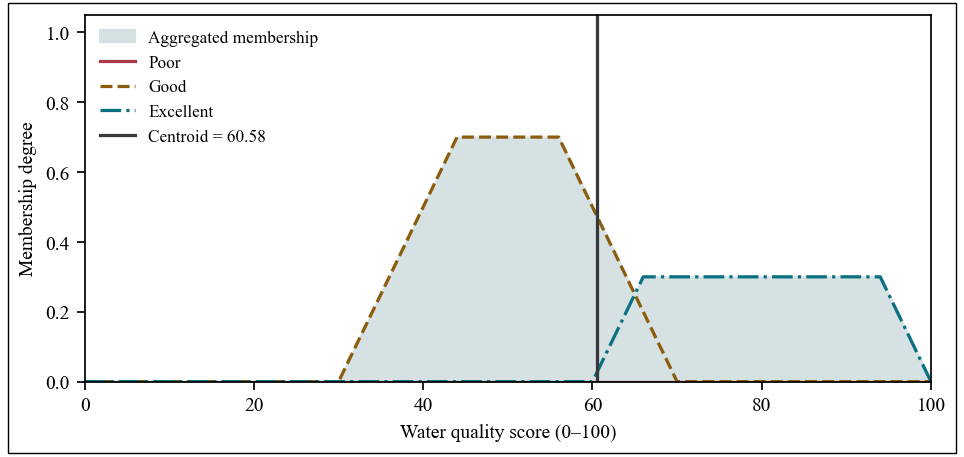

Figure 2 Clipped outputs, aggregation, and centroid for the worked example


In [ ]:
example = np.array([[27, 7.5, 1.68]])
example_degrees = [membership(example[:, i], feature)[0] for i, feature in enumerate(FEATURES)]
display(pd.DataFrame(example_degrees, index=FEATURES, columns=STATES).round(3))
example_labels, example_scores, example_activation = predict(example)
display(pd.Series(example_activation[0], index=PRIORITY, name="Aktivasi").round(3).to_frame())
np.testing.assert_allclose(example_activation[0], [0.0, 0.7, 0.3], atol=1e-10)
aggregated = aggregate_output(example_activation)[0]
weighted_sum = (aggregated * SCORE_GRID).sum()
weight_sum = aggregated.sum()
print(f"Centroid = {weighted_sum:.6f} ÷ {weight_sum:.6f} = {example_scores[0]:.4f}")
print(f"Prediksi: {example_labels[0]}")

fig, ax = new_figure(1, 1, 7.5)
ax.fill_between(SCORE_GRID, aggregated, color="#d6e1e3", label="Aggregated membership")
for label, strength, curve, style in zip(PRIORITY, example_activation[0], output_sets, line_styles):
    ax.plot(SCORE_GRID, np.minimum(strength, curve), style, color=class_colors[label], label=label)
ax.axvline(example_scores[0], color="#35393a", label=f"Centroid = {example_scores[0]:.2f}")
ax.set(xlabel="Water quality score (0–100)", ylabel="Membership degree", ylim=(0, 1.05))
ax.set_xlim(0, 100)
ax.legend(loc="upper left")
save_plot(fig, "figure_02_worked_inference", "Figure 2 Clipped outputs, aggregation, and centroid for the worked example")

## 6. Simulasi perubahan DO

Tetapkan suhu 27 °C dan pH 7,5, lalu ubah DO pada rentang 0–3 mg/L. Grafik memperlihatkan skor yang bertransisi di sekitar 0,5 dan 1,7 mg/L. Simulasi mengisolasi perilaku model ketika hanya DO yang berubah. Titik tepat di pusat transisi mengikuti prioritas seri yang telah ditetapkan.

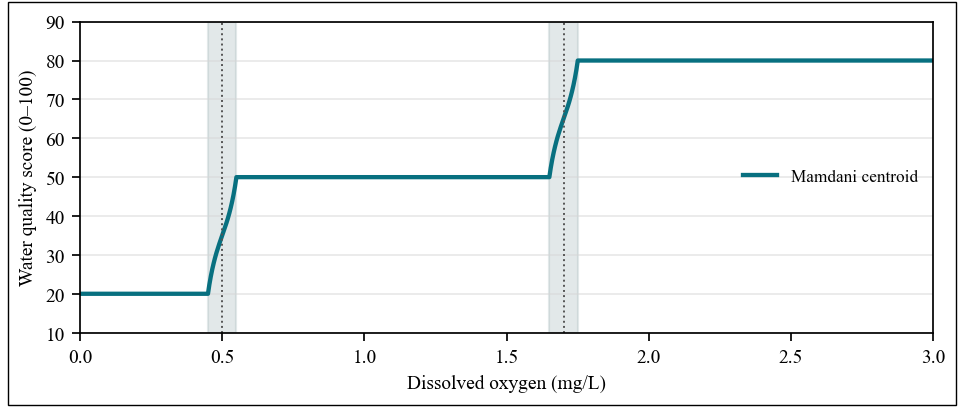

Figure 3 Predicted score response to DO at fixed temperature (27 °C) and pH (7.5)


In [ ]:
oxygen_sweep = np.linspace(0, 3, 601)
sweep_values = np.column_stack([
    np.full(oxygen_sweep.size, 27), np.full(oxygen_sweep.size, 7.5), oxygen_sweep
])
sweep_labels, sweep_scores, _ = predict(sweep_values)
assert np.all(np.diff(sweep_scores) >= -1e-9)

fig, ax = new_figure(1, 1, 6.7)
ax.plot(oxygen_sweep, sweep_scores, color="#087080", linewidth=2, label="Mamdani centroid")
for center in [0.5, 1.7]:
    ax.axvspan(center - 0.05, center + 0.05, color="#a7babc", alpha=0.32)
    ax.axvline(center, color="#545454", linestyle=":", linewidth=0.9)
ax.set(xlabel="Dissolved oxygen (mg/L)", ylabel="Water quality score (0–100)",
       xlim=(0, 3), ylim=(10, 90))
ax.grid(axis="y", alpha=0.55)
ax.legend(loc="center right")
save_plot(fig, "figure_03_do_transition", "Figure 3 Predicted score response to DO at fixed temperature (27 °C) and pH (7.5)")

## 7. Unggah WQD.xlsx mentah dan periksa datanya

Notebook membaca **WQD.xlsx versi 1** dari Mendeley [4]. File tersebut berisi 4.300 sampel dan 14 fitur. Label WQD dibuat dari rentang keempat belas fitur. Kolom **Water Quality** berisi kode 0 (*Excellent*), 1 (*Good*), atau 2 (*Poor*). Nama dan satuan tiga kolom yang dipakai ditampilkan di bawah. Nomor baris mengikuti Excel, dengan data pertama di baris 2.

Pilih file saat kotak unggah muncul. Jika file sudah ada di panel **Files**, kode langsung membacanya. Jika menjalankan di Jupyter lokal, simpan file di folder kerja notebook.

In [ ]:
from importlib.util import find_spec

if find_spec("openpyxl") is None:
    get_ipython().run_line_magic("pip", "install -q openpyxl")

file_wqd = Path("WQD.xlsx")
if not file_wqd.exists():
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError("Letakkan WQD.xlsx di folder kerja notebook.") from error
    print("Pilih file WQD.xlsx versi 1 dari Mendeley.")
    files.upload()
if not file_wqd.exists():
    raise FileNotFoundError("Unggah file dengan nama WQD.xlsx.")

raw = pd.read_excel(file_wqd, engine="openpyxl")
raw.columns = raw.columns.str.strip().str.rstrip(chr(96))
column_mapping = dict(zip(["Temp", "pH", "DO(mg/L)"], FEATURES))
column_mapping["Water Quality"] = "Kode WQD"
if raw.shape != (4300, 15) or not set(column_mapping).issubset(raw.columns):
    raise ValueError("Pakai WQD.xlsx v1 dengan 4.300 baris dan 15 kolom.")

data = raw[list(column_mapping)].rename(columns=column_mapping)
data = data.apply(pd.to_numeric, errors="coerce")
data.index = pd.RangeIndex(2, len(data) + 2, name="Baris Excel")
data["Label WQD"] = data["Kode WQD"].map(dict(enumerate(CLASSES)))
if data["Label WQD"].isna().any():
    raise ValueError("Kode label WQD harus 0, 1, atau 2.")

print(f"Berkas: {file_wqd.name} | Ukuran data mentah: {raw.shape[0]:,} × {raw.shape[1]}")
display(data.head().round(4))

Berkas: WQD.xlsx | Ukuran data mentah: 4,300 × 15


,Temperature (°C),pH,Dissolved oxygen (mg/L),Kode WQD,Label WQD
Baris Excel,,,,,
2,67.4487,4.7517,0.2082,2,Poor
3,64.6267,3.0852,11.4345,2,Poor
4,65.1218,9.6485,12.4309,2,Poor
5,1.6403,4.8200,10.9635,2,Poor
6,64.8634,10.2440,1.3617,2,Poor


### Audit domain, sebaran, dan label

Pemeriksaan domain memakai tiga input. Label WQD dipakai untuk melaporkan kategori baris yang masuk atau keluar, serta untuk mengukur kesesuaian. Jika satu baris gagal dua pemeriksaan input, baris hanya dikeluarkan sekali. Ringkasan distribusi dan konflik label di bawah bersifat deskriptif. Seluruh parameter model sudah ditetapkan di Bagian 1–3.

In [ ]:
eligible = input_domain(data[FEATURES].to_numpy())
wqd_valid = data.loc[eligible].copy()
audit = pd.DataFrame({
    "Total mentah": data["Label WQD"].value_counts(),
    "Dalam domain": wqd_valid["Label WQD"].value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)
audit["Di luar domain"] = audit["Total mentah"] - audit["Dalam domain"]
display(audit)

invalid_by_feature = pd.Series({
    FEATURES[0]: (~data[FEATURES[0]].between(0, 50)).sum(),
    FEATURES[1]: (~data[FEATURES[1]].between(0, 14)).sum(),
    FEATURES[2]: (~(np.isfinite(data[FEATURES[2]]) & data[FEATURES[2]].ge(0))).sum(),
}, name="Baris gagal pemeriksaan")
display(invalid_by_feature.to_frame())
print(f"Cakupan domain: {len(wqd_valid):,}/{len(data):,} ({len(wqd_valid) / len(data):.2%})")

distribution = wqd_valid.groupby("Label WQD")[FEATURES].agg(["min", "median", "max"]).reindex(CLASSES)
display(distribution.round(3))
conflicting_groups = int(wqd_valid.groupby(FEATURES)["Label WQD"].nunique().gt(1).sum())
print(f"Grup input identik dengan label WQD berbeda: {conflicting_groups}")

,Total mentah,Dalam domain,Di luar domain
Label WQD,,,
Excellent,1400,1400,0
Good,1400,1400,0
Poor,1500,1387,113


,Baris gagal pemeriksaan
Temperature (°C),100
pH,16
Dissolved oxygen (mg/L),0


Cakupan domain: 4,187/4,300 (97.37%)


Temperature (°C)                     pH                 \
                       min  median     max    min median     max   
Label WQD                                                          
Excellent           20.007  24.943  29.993  6.500  7.808   9.000   
Good                15.001  25.001  34.992  6.000  7.750   9.499   
Poor                 0.194  24.547  34.992  0.004  7.521  13.653   

          Dissolved oxygen (mg/L)                 
                              min median     max  
Label WQD                                         
Excellent                   3.002  4.011   5.000  
Good                        5.003  6.443   7.995  
Poor                        0.134  4.992  14.970

Grup input identik dengan label WQD berbeda: 200


## 8. Kesesuaian keluaran model dengan label WQD

Jalankan model tetap pada semua sampel dalam domain. **Agreement** adalah persentase label yang sama. **Balanced accuracy** adalah rata-rata *recall* tiga kelas terhadap label WQD. **Macro F1** memberi bobot yang sama pada tiap kelas. *Recall Poor* adalah proporsi sampel WQD berlabel *Poor* yang keluaran modelnya *Poor*. **Angka ini mengukur kesesuaian label WQD**, yang dibentuk dari 14 parameter. Evaluasi lapangan memerlukan label atau penilaian independen pada kondisi budidaya yang sesuai.

In [ ]:
wqd_labels, wqd_scores, _ = predict(wqd_valid[FEATURES])
wqd_valid["Prediksi"] = wqd_labels
wqd_valid["Skor centroid"] = wqd_scores
report = classification_report(
    wqd_valid["Label WQD"], wqd_labels, labels=CLASSES, output_dict=True, zero_division=0
)
metrics = pd.Series({
    "Agreement": report["accuracy"],
    "Balanced accuracy": report["macro avg"]["recall"],
    "Macro F1": report["macro avg"]["f1-score"],
    "Recall Poor": report["Poor"]["recall"],
}, name="Nilai")
display(metrics.round(4).to_frame())

per_class = pd.DataFrame(report).T.loc[CLASSES, ["precision", "recall", "f1-score", "support"]]
per_class["support"] = per_class["support"].astype(int)
display(per_class.round(4))

matrix = confusion_matrix(wqd_valid["Label WQD"], wqd_labels, labels=CLASSES)
display(pd.DataFrame(
    matrix, index=pd.Index(CLASSES, name="Label WQD"), columns=pd.Index(CLASSES, name="Prediksi")
))

,Nilai
Agreement,0.4402
Balanced accuracy,0.4397
Macro F1,0.4445
Recall Poor,0.2870


,precision,recall,f1-score,support
Excellent,0.7640,0.4486,0.5653,1400
Good,0.3418,0.5836,0.4311,1400
Poor,0.4082,0.2870,0.3370,1387


Prediksi,Excellent,Good,Poor
Label WQD,,,
Excellent,628,772,0
Good,6,817,577
Poor,188,801,398


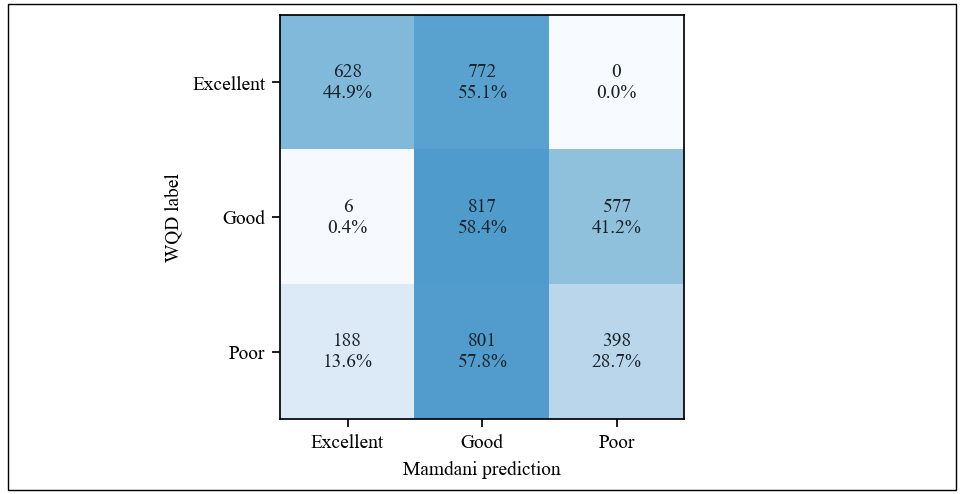

Figure 4 WQD label agreement by class, with counts and row percentages


In [ ]:
fig, ax = new_figure(1, 1, 8.1)
rates = 100 * matrix / matrix.sum(axis=1, keepdims=True)
ax.imshow(rates, cmap="Blues", vmin=0, vmax=100)
ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES,
       xlabel="Mamdani prediction", ylabel="WQD label")
for (row, column), rate in np.ndenumerate(rates):
    color = "white" if rate > 70 else "#172128"
    ax.text(column, row, f"{matrix[row, column]:,}\n{rate:.1f}%",
            ha="center", va="center", color=color)
save_plot(fig, "figure_04_wqd_agreement", "Figure 4 WQD label agreement by class, with counts and row percentages")

### Telusuri satu ketidaksesuaian

Pilih baris pertama yang diberi label *Poor* di WQD dan diklasifikasikan *Excellent* oleh model. Periksa derajat keanggotaan untuk tiga input yang diketahui model. Perbedaan seperti ini memberi contoh bahwa dua definisi kualitas dapat menghasilkan kesimpulan berbeda pada sampel yang sama. Pemeriksaan ini tidak menentukan parameter mana yang menyebabkan label WQD pada baris itu.

In [ ]:
mismatches = wqd_valid.loc[
    (wqd_valid["Label WQD"] == "Poor") & (wqd_valid["Prediksi"] == "Excellent"),
    [*FEATURES, "Label WQD", "Prediksi", "Skor centroid"]
]
if not mismatches.empty:
    first = mismatches.head(1)
    display(first.round(4))
    row = first[FEATURES].to_numpy()
    degrees = [membership(row[:, i], feature)[0] for i, feature in enumerate(FEATURES)]
    display(pd.DataFrame(degrees, index=FEATURES, columns=STATES).round(3))
else:
    print("Tidak ada baris berlabel Poor yang diprediksi Excellent pada file ini.")

,Temperature (°C),pH,Dissolved oxygen (mg/L),Label WQD,Prediksi,Skor centroid
Baris Excel,,,,,,
252,27.2174,7.9433,3.2464,Poor,Excellent,80.0


,Critical,Caution,Optimal
Temperature (°C),0.0,0.0,1.0
pH,0.0,0.0,1.0
Dissolved oxygen (mg/L),0.0,0.0,1.0


## 9. Kesimpulan dan grafik untuk laporan

1. **Perilaku model.** Semua 27 kombinasi status murni dan 11 skenario memberi keluaran yang diharapkan. Pada 1,568 titik uji transisi, setiap sampel punya setidaknya satu aturan aktif. Ini memeriksa konsistensi implementasi.
2. **Kesesuaian WQD.** Model cocok dengan 1,843 dari 4,187 label (44,02%). Dari 1,387 baris dalam domain yang berlabel Poor, 398 diprediksi Poor. Sebanyak 113 baris berlabel Poor berada di luar domain. Ada 200 grup dengan tiga input identik dan label WQD berbeda, sehingga tiga input saja tidak dapat mereproduksi semua label.
3. **Cakupan kesimpulan.** Model menerjemahkan kondisi pada rujukan lele bioflok menjadi penilaian awal tiga indikator. Pengujian skenario bersumber dari definisi yang sama, dan pengujian WQD membandingkan definisi label yang berbeda. Kinerja pada kolam nyata perlu diukur dengan pengamatan dan penilaian independen di konteks yang dituju.

**Ekspor grafik.** Sel terakhir membentuk **Grafik_JMASIF_Mamdani_Literatur.zip**. Ambil dari panel **Files** di Colab. Gambar memakai label Inggris, bingkai, satuan pada sumbu yang relevan, lebar cetak 15,8 cm, dan TIFF 600 dpi. Caption disimpan bersama grafik. Di Word, letakkan caption di bawah gambar dengan Times New Roman 10 pt sesuai template yang dipakai kelompok.

In [ ]:
archive_path = Path("Grafik_JMASIF_Mamdani_Literatur.zip")
with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for path, _ in figures:
        archive.write(path, arcname=path.name)
    archive.writestr("Figure_Captions.txt", "\n\n".join(caption for _, caption in figures) + "\n")
print(f"Paket grafik: {archive_path.name}")

Paket grafik: Grafik_JMASIF_Mamdani_Literatur.zip


### Referensi

1. Pujiharsono, H., & Kurnianto, D. (2020). Sistem inferensi fuzzy Mamdani untuk menentukan tingkat kualitas air pada kolam bioflok dalam budidaya ikan lele. *Jurnal Teknologi dan Sistem Komputer*, 8(2), 84–88. [Artikel lengkap](https://jtsiskom.undip.ac.id/article/download/13209/12555)
2. Michelli, L. M., Alkori, H., Kamal, F., Ramadhan, R. G., Adi, R. M. S., & Burhanuddin, A. (2024). The applications of Mamdani fuzzy in water selection of Pangas catfish ponds. *INISTA*, 6(2), 108–115. [DOI](https://doi.org/10.20895/inista.v6i2.1030)
3. Molato, M. R. D. (2022). AquaStat: An Arduino-based water quality monitoring device for fish kill prevention in tilapia aquaculture using fuzzy logic. *IJACSA*, 13(2), 557–562. [Artikel lengkap](https://thesai.org/Downloads/Volume13No2/Paper_65-AquaStat_An_Arduino_based_Water_Quality_Monitoring_Device.pdf)
4. Veeramsetty, V., Arabelli, R., & Bernatin, T. (2024). *Aquaculture – Water Quality Dataset* (versi 1). Mendeley Data. [Dataset](https://data.mendeley.com/datasets/y78ty2g293/1)
5. Mamdani, E. H., & Assilian, S. (1975). An experiment in linguistic synthesis with a fuzzy logic controller. *International Journal of Man-Machine Studies*, 7(1), 1–13. [DOI](https://doi.org/10.1016/S0020-7373(75)80002-2)